<a href="https://colab.research.google.com/github/RainanCoelho/Projeto-Analise-Exploratoria-Grupo8-Gestao_de_Vendedores-Parceiros/blob/main/Dataset_olist_products_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**FRENTE 1**

In [1]:
import pandas as pd
import numpy as np

URL = "https://raw.githubusercontent.com/RainanCoelho/Projeto-Analise-Exploratoria-Grupo8-Gestao_de_Vendedores-Parceiros/refs/heads/main/olist_products_dataset.csv"
df_opd = pd.read_csv(URL)
df_opd.columns = ["product_id","product_category_name","product_name_lenght","product_description_lenght","product_photos_qty","product_weight_g","product_length_cm","product_height_cm","product_width_cm"]
df_opd.head(5)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


PARTE 1: CONHECIMENTO DOS DADOS

In [2]:
df_opd.shape #Mostra no console a quantidade de linhas e colunas do dataset

(32951, 9)

In [3]:
df_opd.info() #Mostra o tipo e a quantidade de valores não nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [4]:
df_opd.describe() #Mostra a estatística das tabelas, como média, valor máximo, mínimo, valores interquartis e mais

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [5]:
df_opd.dtypes #Mostra os tipos dos valores de cada coluna

,0
product_id,object
product_category_name,object
product_name_lenght,float64
product_description_lenght,float64
product_photos_qty,float64
product_weight_g,float64
product_length_cm,float64
product_height_cm,float64
product_width_cm,float64


PARTE 2: CORREÇÃO DOS TIPOS

In [6]:
def corrigir_tipos_colunas(df):
  df = df.copy()
  coluna_corrigir = ["product_name_lenght", "product_description_lenght", "product_photos_qty"]
  for coluna in coluna_corrigir:
    df[coluna] = df[coluna].astype("Int64")
  return df

df_opd = corrigir_tipos_colunas(df_opd)
df_opd.dtypes

,0
product_id,object
product_category_name,object
product_name_lenght,Int64
product_description_lenght,Int64
product_photos_qty,Int64
product_weight_g,float64
product_length_cm,float64
product_height_cm,float64
product_width_cm,float64


**EXPLICAÇÃO**: Altera o tipo dos dados das colunas: "product_name_lenght", "product_description_lenght" e "product_photos_qty", já que elas estavam marcando como float, mas faz mais sentido elas serem lidas do tipo inteiro

PARTE 3: Padronização de nomes

In [7]:
def padronizar_categoria(df):
  df = df.copy()
  df["product_category_name"] = df["product_category_name"].str.strip().str.lower()
  return df

df_opd = padronizar_categoria(df_opd)

**EXPLICAÇÃO**: Essa função serve para padronizar os nomes da coluna: "product_category_name", para que não haja erro na leitura dos nomes

PARTE 4: VERIFICAÇÃO DE DUPLICADAS E ID

In [8]:
df_opd.isnull().sum() #Verifica a quantidade de valores nulos por coluna

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


**RESPOSTA**: Foi verificado 610 valores nulos nas colunas: product_category_name,	product_name_lenght,	product_description_lenght e product_photos_qty, e 2 valores nulos nas colunas: product_weight_g,	product_length_cm,	product_height_cm e	product_width_cm e foi verificado que e a coluna product_id não tem nenhum valor duplicado

In [9]:
print("product_id duplicado:", df_opd["product_id"].duplicated().sum())
print("product_id nulo:", df_opd["product_id"].isnull().sum())

product_id duplicado: 0
product_id nulo: 0


**EXPLICAÇÃO**: Esse comando serve para ver se existe algum valor duplicado ou nulo na coluna "product_id"

In [10]:
colunas = ["product_category_name", "product_name_lenght", "product_description_lenght", "product_photos_qty"]
print("Linhas com as 4 colunas vazias:", df_opd[colunas].isnull().all(axis=1).sum())

Linhas com as 4 colunas vazias: 610


**EXPLICAÇÃO**: Esse comando busca entender se os 610 valores nulos pertencem a um mesmo produto, ou seja, existem 610 linhas onde os valores das colunas estão nulas na mesma linha

In [11]:
medidas = ["product_weight_g", "product_length_cm", "product_height_cm","product_width_cm"]
print("Linhas com 4 medidas vazias:", df_opd[medidas].isnull().all(axis=1).sum())

Linhas com 4 medidas vazias: 2


**EXPLICAÇÃO**: Esse comando busca entender se os 2 valores nulos pertencem a um mesmo produto, ou seja, existem 2 linhas onde os valores das colunas estão nulas na mesma linha

In [12]:
df_opd.duplicated().sum() #Verifica se existe algum valor duplicado na tabela

np.int64(0)

**RESPOSTA**: Não foi verificado nenhuma linha duplicada na tabela

PARTE 5: VERIFICAÇÃO DE VALORES IMPOSSÍVEIS

In [13]:
colunas= ["product_name_lenght","product_description_lenght","product_photos_qty","product_weight_g","product_length_cm","product_height_cm","product_width_cm"]
for coluna in colunas:
  print((df_opd[coluna] <= 0).sum())

0
0
0
4
0
0
0


**EXPLICAÇÃO**: Esse comando busca ver se nas tabelas de valor numérico existe algum valor nulo ou abaixo de 0

In [14]:
def anular_peso_zero(df):
  df = df.copy()
  df.loc[df["product_weight_g"] == 0, "product_weight_g"] = np.nan
  return df

print("Antes:", (df_opd["product_weight_g"] == 0).sum())
df_opd = anular_peso_zero(df_opd)
print("Depois:", (df_opd["product_weight_g"] == 0).sum())

Antes: 4
Depois: 0


**EXPLICAÇÃO**: Os 4 valores que estão exatamente iguais a 0 na coluna "product_weight_g" foram substituidos como valores nulos, mas não excluídos, já que a exclusão dos mesmos iria fazer uma intervenção mínima no sistema

PARTE 6: Verificação de valores Outlier

In [15]:
def verificar_outliers(df):
  colunas = ["product_name_lenght","product_description_lenght","product_photos_qty","product_weight_g","product_length_cm","product_height_cm","product_width_cm"]
  for coluna in colunas:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    outlier = df[(df[coluna] > limite_sup) | (df[coluna] < limite_inf)]
    acima = df[df[coluna] > limite_sup]
    abaixo = df[df[coluna] < limite_inf]
    print(coluna, "| acima:", len(acima), "| abaixo:", len(abaixo))


verificar_outliers(df_opd)

product_name_lenght | acima: 0 | abaixo: 290
product_description_lenght | acima: 2078 | abaixo: 0
product_photos_qty | acima: 849 | abaixo: 0
product_weight_g | acima: 4551 | abaixo: 0
product_length_cm | acima: 1380 | abaixo: 0
product_height_cm | acima: 1892 | abaixo: 0
product_width_cm | acima: 912 | abaixo: 0


**EXPLICAÇÃO**: Com base nos parâmetros IQR,  foi notado que em todas as colunas de peso e medidas: 4.551 produtos acima de 4.300 g, 1.380 acima de 68 cm de comprimento, 1.892 acima de 40,5 cm de altura e 912 acima de 52,5 cm de largura. E os valores que foram identificados como outliers, eles podem ser facilmente aceitos levando em conta a diferença de produtos cadastrados, então uma exclusão de dados outliers não seria a melhor opção

**FRENTE 2**


PARTE 7: CRIAÇÃO DE NOVOS ATRIBUTOS (FEATURE ENGINEERING)

In [16]:
def criar_features_products(df):
    out = df.copy()

    # Calcula o volume cúbico da embalagem (comprimento x altura x largura)
    out["volume_cm3"] = (
        out["product_length_cm"] * out["product_height_cm"] * out["product_width_cm"]
    )

    # Calcula a densidade (peso por cm³), evitando divisão por zero
    out["densidade_g_cm3"] = np.where(
        out["volume_cm3"] > 0,
        out["product_weight_g"] / out["volume_cm3"],
        np.nan,
    )

    # Flag binária (1/0) indicando se o produto tem categoria, fotos e peso preenchidos
    out["flag_cadastro_completo"] = (
        out["product_category_name"].notna()
        & out["product_photos_qty"].notna()
        & out["product_weight_g"].notna()
    ).astype(int)

    # Flag binária (1/0) para produtos pesados acima de 4.300 g (corte IQR da Frente 1)
    out["flag_produto_pesado"] = np.where(
        out["product_weight_g"].notna(),
        (out["product_weight_g"] > 4300).astype(int),
        np.nan,
    )

    return out


# Gera o novo DataFrame com as features criadas
df_opd_f2 = criar_features_products(df_opd)

novas_cols = [
    "volume_cm3",
    "densidade_g_cm3",
    "flag_cadastro_completo",
    "flag_produto_pesado",
]

# Exibe estatísticas descritivas e contagem de nulos das novas colunas
print(df_opd_f2[novas_cols].describe())
print("\nNulos nas novas colunas:")
print(df_opd_f2[novas_cols].isna().sum())

          volume_cm3  densidade_g_cm3  flag_cadastro_completo  \
count   32949.000000     32945.000000            32951.000000   
mean    16564.096695         0.203714                0.981336   
std     27057.041650         1.009329                0.135338   
min       168.000000         0.000220                0.000000   
25%      2880.000000         0.066204                1.000000   
50%      6840.000000         0.116550                1.000000   
75%     18480.000000         0.195869                1.000000   
max    296208.000000        85.227273                1.000000   

       flag_produto_pesado  
count         32945.000000  
mean              0.138139  
std               0.345051  
min               0.000000  
25%               0.000000  
50%               0.000000  
75%               0.000000  
max               1.000000  

Nulos nas novas colunas:
volume_cm3                2
densidade_g_cm3           6
flag_cadastro_completo    0
flag_produto_pesado       6
dtype: int64


**EXPLICAÇÃO**: A partir das medidas, do peso e dos dados de cadastro dos produtos, foram criadas quatro colunas novas para ajudar a entender se produtos maiores ou mal cadastrados geram mais atrasos e notas piores para os vendedores. Foi visto que o volume médio dos produtos é de 16.564 cm³, com densidade média de 0,20 g por cm³, e que cerca de 13,8% dos itens são considerados pesados acima de 4.300 g. Também foi observado que 98,1% dos produtos estão com o cadastro completo de categoria, fotos e peso, restando poucos nulos apenas nos produtos que já não tinham peso ou medidas na base.

PARTE 8: CODIFICAÇÃO DE DADOS CATEGÓRICOS

In [18]:
def codificar_products(df):
    out = df.copy()

    # Agrupa as categorias mantendo as 5 principais e juntando o restante em "outras"
    top_5 = out["product_category_name"].value_counts().head(5).index.tolist()
    out["categoria_grupo"] = np.where(
        out["product_category_name"].isna(),
        "sem_categoria",
        np.where(out["product_category_name"].isin(top_5), out["product_category_name"], "outras"),
    )

    # Transforma categoria_grupo em colunas binárias (0 e 1) mantendo a coluna original
    dummies = pd.get_dummies(out["categoria_grupo"], prefix="cat", dtype=int)
    out = pd.concat([out, dummies], axis=1)

    return out


cols_originais = set(df_opd_f2.columns)
df_opd_f2 = codificar_products(df_opd_f2)
novas_cols = [col for col in df_opd_f2.columns if col not in cols_originais]

# Exibe as novas colunas, contagens por grupo de categoria e primeiras linhas
print("Novas colunas:", novas_cols)
print("\nContagem por grupo de categoria:")
print(df_opd_f2["categoria_grupo"].value_counts())
print("\nPrimeiras linhas:")
print(df_opd_f2[novas_cols].head())

Novas colunas: ['categoria_grupo', 'cat_beleza_saude', 'cat_cama_mesa_banho', 'cat_esporte_lazer', 'cat_moveis_decoracao', 'cat_outras', 'cat_sem_categoria', 'cat_utilidades_domesticas']

Contagem por grupo de categoria:
categoria_grupo
outras                   19009
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
sem_categoria              610
Name: count, dtype: int64

Primeiras linhas:
         categoria_grupo  cat_beleza_saude  cat_cama_mesa_banho  \
0                 outras                 0                    0   
1                 outras                 0                    0   
2          esporte_lazer                 0                    0   
3                 outras                 0                    0   
4  utilidades_domesticas                 0                    0   

   cat_esporte_lazer  cat_moveis_decoracao  cat_outras  cat_sem_categoria  \
0                  0 

**EXPLICAÇÃO**: Como a coluna de categoria possui mais de 70 nomes diferentes e o código product_id precisa ficar intacto para o cruzamento futuro, as categorias menos frequentes foram agrupadas em outras e os produtos sem nome de categoria ficaram marcados como sem_categoria. Mantendo as cinco maiores categorias separadas, esse grupo foi transformado em sete colunas numéricas de 0 e 1, preservando a coluna categoria_grupo original para facilitar filtros. Foi visto que 19.009 produtos ficaram em outras, 610 em sem_categoria e o restante nas cinco categorias principais lideradas por cama_mesa_banho com 3.029 itens.

PARTE 9: NORMALIZAÇÃO E PADRONIZAÇÃO

In [19]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler


def escalonar_products(df, colunas):
    out = df.copy()

    # Garante formato numérico e evita valores infinitos
    dados_num = out[colunas].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)

    minmax_scaler = MinMaxScaler()
    standard_scaler = StandardScaler()

    minmax_vals = minmax_scaler.fit_transform(dados_num)
    zscore_vals = standard_scaler.fit_transform(dados_num)

    # Atribui coluna por coluna mantendo os valores originais intactos
    for i, col in enumerate(colunas):
        out[f"{col}_minmax"] = minmax_vals[:, i]
        out[f"{col}_zscore"] = zscore_vals[:, i]

    return out


cols_escalar = [
    "product_weight_g",
    "volume_cm3",
    "densidade_g_cm3",
    "product_photos_qty",
    "product_description_lenght",
]

df_opd_f2 = escalonar_products(df_opd_f2, cols_escalar)

cols_escalonadas = [f"{col}_minmax" for col in cols_escalar] + [
    f"{col}_zscore" for col in cols_escalar
]
print(df_opd_f2[cols_escalonadas].describe())

       product_weight_g_minmax  volume_cm3_minmax  densidade_g_cm3_minmax  \
count             32945.000000       32949.000000            32945.000000   
mean                  0.056274           0.055385                0.002388   
std                   0.105935           0.091397                0.011843   
min                   0.000000           0.000000                0.000000   
25%                   0.007372           0.009161                0.000774   
50%                   0.017267           0.022537                0.001365   
75%                   0.046953           0.061857                0.002296   
max                   1.000000           1.000000                1.000000   

       product_photos_qty_minmax  product_description_lenght_minmax  \
count               32341.000000                       32341.000000   
mean                    0.062578                           0.192451   
std                     0.091409                           0.159257   
min                   

**EXPLICAÇÃO**: As cinco colunas numéricas principais de peso, volume, densidade, quantidade de fotos e tamanho da descrição foram colocadas nas escalas MinMax, entre 0 e 1, e Z-score, com média 0 e desvio padrão 1, gerando dez colunas novas e mantendo os valores originais em gramas, centímetros e quantidades. Todos os registros válidos e nulos das colunas originais foram preservados, permitindo identificar produtos com volume e densidade muito fora do padrão, chegando a mais de 10 desvios acima da média no volume e mais de 84 na densidade.

PARTE 10: SELEÇÃO DE ATRIBUTOS

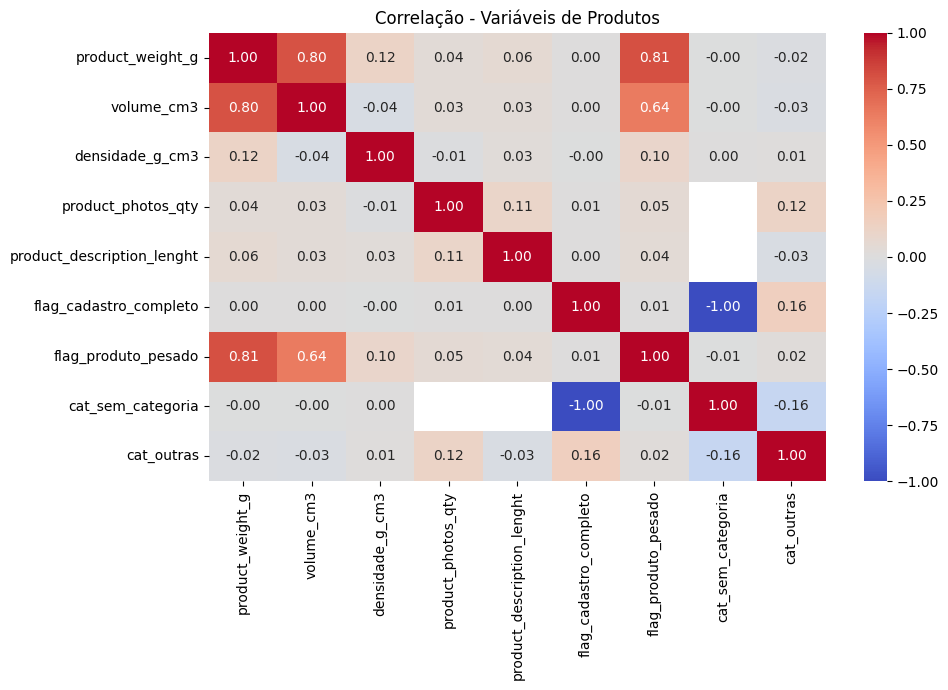

Colunas com variância <= 0.01: []
Shape antes: (32951, 31)
Shape depois: (32951, 30)
Colunas finais: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'volume_cm3', 'densidade_g_cm3', 'flag_cadastro_completo', 'flag_produto_pesado', 'categoria_grupo', 'cat_beleza_saude', 'cat_cama_mesa_banho', 'cat_esporte_lazer', 'cat_moveis_decoracao', 'cat_outras', 'cat_utilidades_domesticas', 'product_weight_g_minmax', 'product_weight_g_zscore', 'volume_cm3_minmax', 'volume_cm3_zscore', 'densidade_g_cm3_minmax', 'densidade_g_cm3_zscore', 'product_photos_qty_minmax', 'product_photos_qty_zscore', 'product_description_lenght_minmax', 'product_description_lenght_zscore']


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold

cols_num = [
    "product_weight_g",
    "volume_cm3",
    "densidade_g_cm3",
    "product_photos_qty",
    "product_description_lenght",
    "flag_cadastro_completo",
    "flag_produto_pesado",
    "cat_sem_categoria",
    "cat_outras",
]

# 1. Heatmap de correlação das variáveis numéricas (sem as escalonadas)
plt.figure(figsize=(10, 7))
sns.heatmap(df_opd_f2[cols_num].astype(float).corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação - Variáveis de Produtos")
plt.tight_layout()
plt.show()

# 2. Verifica se há colunas com variância muito baixa (<= 0.01) em cópia temporária imputada pela mediana
cols_cat = [c for c in df_opd_f2.columns if c.startswith("cat_")]
cols_vt = [
    "product_weight_g",
    "volume_cm3",
    "densidade_g_cm3",
    "product_photos_qty",
    "product_description_lenght",
    "flag_cadastro_completo",
    "flag_produto_pesado",
] + cols_cat

df_vt_temp = df_opd_f2[cols_vt].astype(float).copy()
df_vt_temp = df_vt_temp.fillna(df_vt_temp.median(numeric_only=True))

vt = VarianceThreshold(threshold=0.01)
vt.fit(df_vt_temp)

baixa_variancia = [col for col, keep in zip(cols_vt, vt.get_support()) if not keep]
print("Colunas com variância <= 0.01:", baixa_variancia)


# 3. Remove cat_sem_categoria por ter correlação -1.00 (inversa) com flag_cadastro_completo
def selecionar_atributos_products(df, cols_remover=None):
    out = df.copy()
    if cols_remover is None:
        cols_remover = ["cat_sem_categoria"]
    return out.drop(columns=cols_remover, errors="ignore")


print("Shape antes:", df_opd_f2.shape)
df_opd_sel = selecionar_atributos_products(df_opd_f2)
print("Shape depois:", df_opd_sel.shape)
print("Colunas finais:", list(df_opd_sel.columns))

**EXPLICAÇÃO**: O gráfico de calor mostrou que cat_sem_categoria tinha correlação inversa exata de menos 1,00 com a bandeira de cadastro completo, funcionando como informação repetida na tabela. O teste de variação confirmou que nenhuma das colunas numéricas analisadas possui variação baixa demais. Por isso, a coluna cat_sem_categoria foi removida, reduzindo a tabela de 31 para 30 colunas e mantendo todos os 32.951 produtos com o código de identificação, categoria e características principais prontos para o cruzamento final.